# 二维 TCW 谱

本例使用 $64^2$ 网格。持续加噪与首步加噪各 64 对轨迹，$\theta=10^{-5}$，首步加噪后从 $t_0^*=8$ 起关闭噪声。

令 $\omega(q)=-s(q)$，其中 $s$ 使用连续空间色散关系且 $a=0$。平膜起始的持续加噪谱功率为
$$S(q,t)=\frac{2\theta}{L^2\gamma q^2}(1-e^{-2\omega(q)t}).$$
首步加噪以实测首谱 $S_0(q)$ 为初值，后续功率为 $S_0(q)e^{-2\omega(q)(t-t_0)}$。理论和数值都先对同一组 Fourier 壳内的功率平均，再开方。计算入口见 [run_tcw.py](run_tcw.py)。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

root = Path.cwd()
if not (root / "data").is_dir():
    root = root / "postprocess"
sys.path.insert(0, str(root))
from plot_style import setup
setup()

# Replace this path with the tcw.csv generated by a larger run.
data_path = root / "data" / "tcw_64_continuous.csv"
data = np.genfromtxt(data_path, delimiter=",", names=True)
assert len(data) == 6*len(np.unique(data["shell"]))
on = data[data["protocol"] == 0]
print(f"Maximum continuous-noise RMS difference: {np.max(abs(on['rms_jam']/on['rms_theory']-1)):.2%}")


Maximum continuous-noise RMS difference: 5.35%


## 持续加噪与首步加噪

空白填充圆点为 JAM，实心圆点为 Basilisk。下方虚线从实测首谱起算。

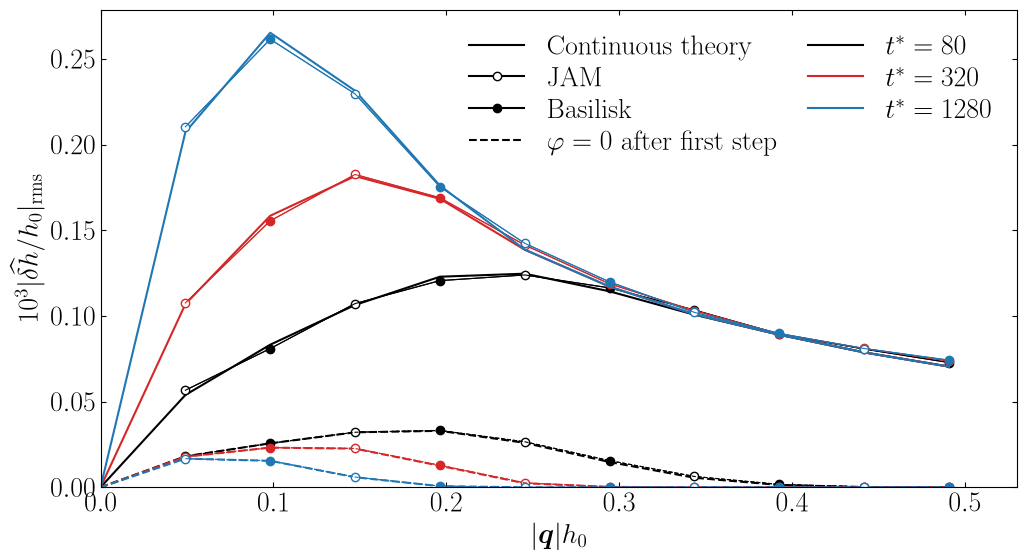

In [2]:

fig, ax = plt.subplots(figsize=(32/3, 6))
times = (80, 320, 1280)
colors = ("#000000", "#D62728", "#1F77B4")
for protocol, line in ((0, "-"), (1, "--")):
    for time, color in zip(times, colors):
        rows = data[(data["protocol"] == protocol) & (data["time"] == time)]
        q = rows["q"]
        ax.plot(np.r_[0.,q], 1e3*np.r_[0.,rows["rms_theory"]], line, color=color)
        for field, fill, offset in (("rms_jam","white",0), ("rms_basilisk",color,1)):
            ax.plot(q, 1e3*rows[field], line, color=color, marker="o", markerfacecolor=fill,
                    markevery=(offset,2), linewidth=.8)
handles = [
    Line2D([], [], color="black", label="Continuous theory"),
    Line2D([], [], color="black", marker="o", markerfacecolor="white", label="JAM"),
    Line2D([], [], color="black", marker="o", label="Basilisk"),
    Line2D([], [], color="black", linestyle="--", label=r"$\varphi=0$ after first step"),
    *(Line2D([], [], color=color, label=rf"$t^*={t}$") for color,t in zip(colors,times)),
]
ax.legend(handles=handles, loc="upper right", ncols=2, columnspacing=1.1, labelspacing=.25)
ax.set(xlabel=r"$|\boldsymbol{q}|h_0$", ylabel=r"$10^3|\widehat{\delta h}/h_0|_{\rm rms}$",
       xlim=(0,.53), ylim=(0.,None))
ax.tick_params(direction="in", top=True, right=True)
ax.grid(False, which="both")
fig.tight_layout()
fig.savefig(root / "figures" / "tcw_continuous.png", dpi=600)
fig.savefig(root / "figures" / "tcw_continuous.pdf")
plt.show()


图为已完成的 64 格示例。持续加噪谱相对连续理论的最大振幅差约为 5.4%。512 格短测用于计时。